In [27]:
from src.data_generator import DataGenerator
from src.gaussian_mixture import GaussianMixtureMAR
from src.motivating_example import UtoM
import numpy as np
import torch
from src.metrics import energy_distance_faster

from joblib import Parallel, delayed
import matplotlib.pyplot as plt

In [28]:
import torch
import numpy as np
import rpy2.robjects as ro
from src.r_funcs import r_ampute
from rpy2.robjects.packages import importr

from src.converter import Converter


# import os
# from pathlib import Path
# R_HOME = Path(r"C:\Users\hu\AppData\Local\Programs\R\R-4.5.3")
# assert (R_HOME / "bin" / "R.exe").exists(), "R.exe not found"
# assert (R_HOME / "bin" / "x64" / "R.dll").exists(), "R.dll not found"
# os.environ["R_HOME"] = str(R_HOME)
# os.environ["PATH"] = (
#     str(R_HOME / "bin" / "x64")
#     + os.pathsep
#     + str(R_HOME / "bin")
#     + os.pathsep
#     + os.environ["PATH"]
# )


mice = importr("mice")


class AmputeMAR(Converter):

    def __init__(self, n:int, d:int, n_pat:int, seed:int):
        super().__init__()

        if n_pat < 1:
            raise ValueError('Number of patterns should be at least 1')

        self.n = n
        self.d = d
        self.n_pat = n_pat # number of patterns
        self.seeds = np.random.SeedSequence(seed).spawn(3)
        self.rng, self.rng_amp, self.rng_eps = [np.random.default_rng(s) for s in self.seeds]
        self.seed_amp = int(self.rng_amp.integers(1, 2**31 - 1))
        self.seed_eps = int(self.rng_eps.integers(1, 2**31 - 1))
        self.patterns = self.sample_patterns()


    def sample_patterns(self) -> np.array:
        """Sample incomplete missingness patterns once (1 = observed, 0 = missing).
        Last column is always observed; all-ones rows are excluded."""
        while True:
            if self.n_pat is None:
                self.n_pat = int(self.rng.integers(3, max(round(n / 100), 3) + 1))

            patterns = self.rng.integers(0, 2, size=(self.n_pat, d - 1))
            # last column is always observed
            patterns = np.hstack([patterns, np.ones((self.n_pat, 1), dtype=int)])
            incomplete = patterns[~patterns.all(axis=1)]
            if incomplete.shape[0] > 0:
                return incomplete


    def ampute(self, X:torch.tensor, prop:float = None, miss_mech:str = 'MAR', miss_type: str = 'RIGHT', weights = None) -> tuple:
        """
        Parameters
        ----------
        X : torch.Tensor, shape (n, d)
            Complete data.

        prop : float, optional
            Proportion of cases with missing values (so 1 - prop stay complete).
            Default: n_pats / (n_pats + 1), i.e. the complete cases are as
            frequent as each incomplete pattern.

        miss_type : str
            RIGHT:
            ...

        Returns
        -------
        X_NA : torch.Tensor
            Data with NaN values.
        M : torch.Tensor
            Observation mask: 1 = observed, 0 = missing.
        """

        n_pats = len(self.patterns)

        if prop is None:
            prop = n_pats / (n_pats + 1)

        if n_pats > 0:
            result = r_ampute(
                self.to_r(X),
                patterns=self.to_r(self.patterns),
                prop=prop,              # freq defaults to equal across patterns
                mech=miss_mech,
                bycases=True,
                type=self.to_r(miss_type),
                weights=self.to_r(weights),
                seed=self.seed_amp
            )
            # amp = self.to_python(result.rx2("amp"))
            # amp = amp.to_numpy() if hasattr(amp, "to_numpy") else np.asarray(amp)
            X_NA = torch.tensor(self.to_python(result.rx2("amp")), device=X.device, dtype=X.dtype)   # (n, d)

        M = ~torch.isnan(X_NA)

        return X_NA, M
    

    def ampute_eps(self, X:torch.tensor, c0:float = 0.01, eps:float = None):
        # mask1: complete case
        complete = self.rng_eps.random(self.n) < c0
        # mask2: mnar
        mnar = ~complete & (self.rng_eps.random(self.n) < eps / (1 - c0))   # gives eps*n MNAR rows on average
        # mask3: mar
        mar = ~complete & ~mnar

        X_NA = X.detach().cpu().numpy()
        for mask, mech, s in zip([mnar, mar], ['MNAR', 'MAR'], [self.seed_eps, self.seed_eps+1]):
            if mask.sum() == 0:
                continue
            X_NA[mask] = self.to_python(r_ampute(
                self.to_r(X[mask]),
                patterns = self.to_r(self.patterns),
                mech = mech,
                seed = s
                ).rx2("amp"))

        X_NA = torch.tensor(X_NA, device=X.device, dtype=X.dtype)

        M = (~torch.isnan(X_NA)).int()

        return X_NA, M, complete, mnar, mar

In [29]:
class MissingDataGenerator(DataGenerator, AmputeMAR, UtoM):

    def __init__(self, 
                 n:int, d:int,
                 n_pat:int, seed:int,
                 distr = "normal", mu = None, sigma = None, pi = None, alpha = 0.7, c = 0.01, df = None, device = "cpu", dtype=torch.float64):
        DataGenerator.__init__(self, distr=distr, mu=mu, sigma=sigma, pi=pi, alpha=alpha, c=c, df=df, device=device, dtype=dtype)
        AmputeMAR.__init__(self, n=n, d=d, n_pat=n_pat, seed=seed)
        UtoM.__init__(self, d=d)
        self.n = n
        self.d = d

    def get_X(self):
        return self.sample_truth(n=self.n, d=self.d)

    def get_M_ampute_eps(self, X, eps):
        Xmis, M, _, _, _ = self.ampute_eps(X, eps=eps)
        return Xmis, M

    def get_M_eps_contaminated_mar(self, X, eps):
        u1 = self.x_to_u(X[:,0])
        u2 = self.x_to_u(X[:,1])
        M = self.get_M(missing_type='contaminated_mar', u1=u1, u2=u2, eps=eps)
        return M

In [30]:
n = 2000
d = 20
n_pat = 3
k_range = (0,20)
eps_vals = [0.0, 0.1, 0.2, 0.5, 0.7, 0.9]
B = 2

In [31]:
mdg = MissingDataGenerator(n=n, d=d, n_pat=n_pat, seed=1, distr='logistic')

In [32]:
def job(
        k_range:tuple = None,
        eps:int = None
):
    X = mdg.get_X()
    _, M = mdg.get_M_ampute_eps(X, eps=eps)
    Xtest = mdg.get_X()
    model = GaussianMixtureMAR(k_range=k_range)
    model.fit(X, M)
    Xtilde = model.sample(n)[0]
    return energy_distance_faster(Xtest, Xtilde, scale=True).item()

In [33]:
results = np.empty((B, len(eps_vals)))

In [34]:
for b in range(B):
    for i, eps in enumerate(eps_vals):
        results[b, i] = job(k_range=k_range, eps=eps)

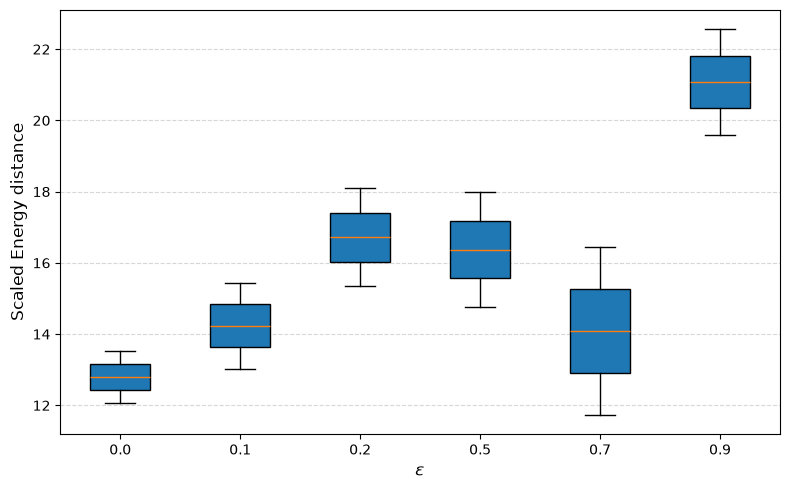

In [47]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(results, tick_labels=eps_vals, patch_artist=True)

ax.set_ylabel("Scaled Energy distance", fontsize=12)
ax.set_xlabel(r"$\epsilon$", fontsize=12)

ax.tick_params(axis="both", labelsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.5)

fig.tight_layout()

plt.savefig(f'results/density_estimation_{n_pat}_patterns_{B}_B.png',dpi=300,
    bbox_inches="tight",)

plt.show()